In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from prophet import Prophet

c:\Users\Kuldeep\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv("cleaned_retail.csv")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,RollingAvgSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,NaN
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,NaN
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,NaN
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,NaN
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,19.664


In [4]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalPrice', 'RollingAvgSales']


In [5]:
print(df["InvoiceDate"].dtype)
print(df["InvoiceDate"].head())

str
0    2010-12-01 08:26:00
1    2010-12-01 08:26:00
2    2010-12-01 08:26:00
3    2010-12-01 08:26:00
4    2010-12-01 08:26:00
Name: InvoiceDate, dtype: str


In [6]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

In [7]:
print(df["InvoiceDate"].dtype)
print(df["InvoiceDate"].isna().sum())

datetime64[us]
0


In [8]:
daily_sales = (
    df.groupby(df["InvoiceDate"].dt.date)["TotalPrice"]
      .sum()
      .reset_index()
)

daily_sales.head()

,InvoiceDate,TotalPrice
0,2010-12-01,46192.49
1,2010-12-02,47197.57
2,2010-12-03,23876.63
3,2010-12-05,31361.28
4,2010-12-06,31009.33


In [9]:
daily_sales.columns = ["ds", "y"]

daily_sales.head()

,ds,y
0,2010-12-01,46192.49
1,2010-12-02,47197.57
2,2010-12-03,23876.63
3,2010-12-05,31361.28
4,2010-12-06,31009.33


In [10]:
model = Prophet()
model.fit(daily_sales)

22:38:33 - cmdstanpy - INFO - Chain [1] start processing
22:38:34 - cmdstanpy - INFO - Chain [1] done processing


In [11]:
future = model.make_future_dataframe(periods=90)
future.tail()

,ds
390,2012-03-04
391,2012-03-05
392,2012-03-06
393,2012-03-07
394,2012-03-08


In [12]:
forecast = model.predict(future)
forecast.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2010-12-01,24303.640789,5751.537027,40720.660442,24303.640789,24303.640789,-779.432825,-779.432825,-779.432825,-779.432825,-779.432825,-779.432825,0.0,0.0,0.0,23524.207964
1,2010-12-02,24308.125739,13198.171874,47109.748933,24308.125739,24308.125739,6484.397811,6484.397811,6484.397811,6484.397811,6484.397811,6484.397811,0.0,0.0,0.0,30792.523550
2,2010-12-03,24312.610689,6108.093209,40205.711880,24312.610689,24312.610689,-1491.858950,-1491.858950,-1491.858950,-1491.858950,-1491.858950,-1491.858950,0.0,0.0,0.0,22820.751739
3,2010-12-05,24321.580590,-9375.705468,26380.048779,24321.580590,24321.580590,-15064.065283,-15064.065283,-15064.065283,-15064.065283,-15064.065283,-15064.065283,0.0,0.0,0.0,9257.515307
4,2010-12-06,24326.065540,5188.204422,40688.843019,24326.065540,24326.065540,-2010.943499,-2010.943499,-2010.943499,-2010.943499,-2010.943499,-2010.943499,0.0,0.0,0.0,22315.122041


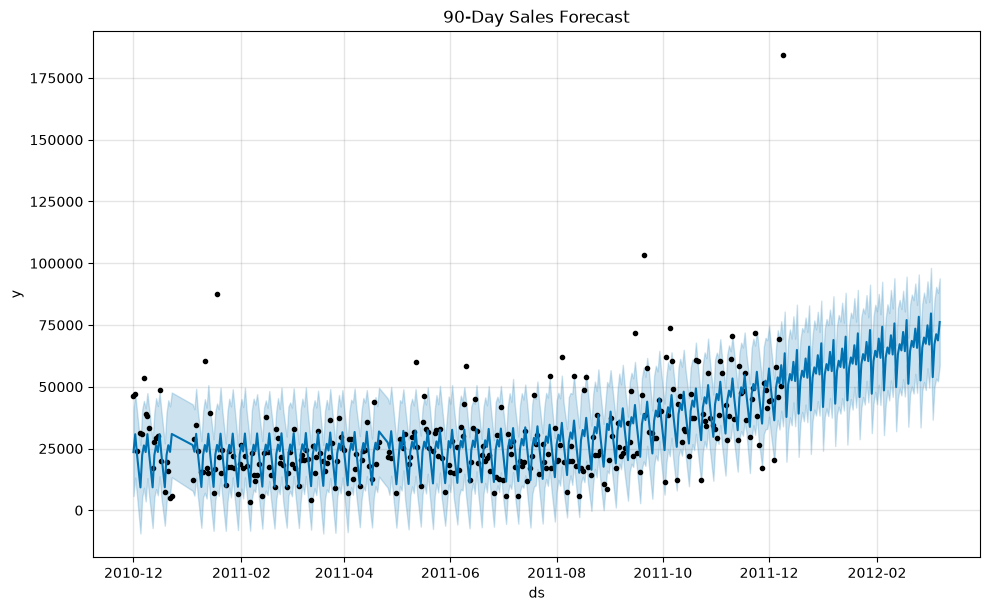

In [13]:
fig = model.plot(forecast)
plt.title("90-Day Sales Forecast")
plt.show()

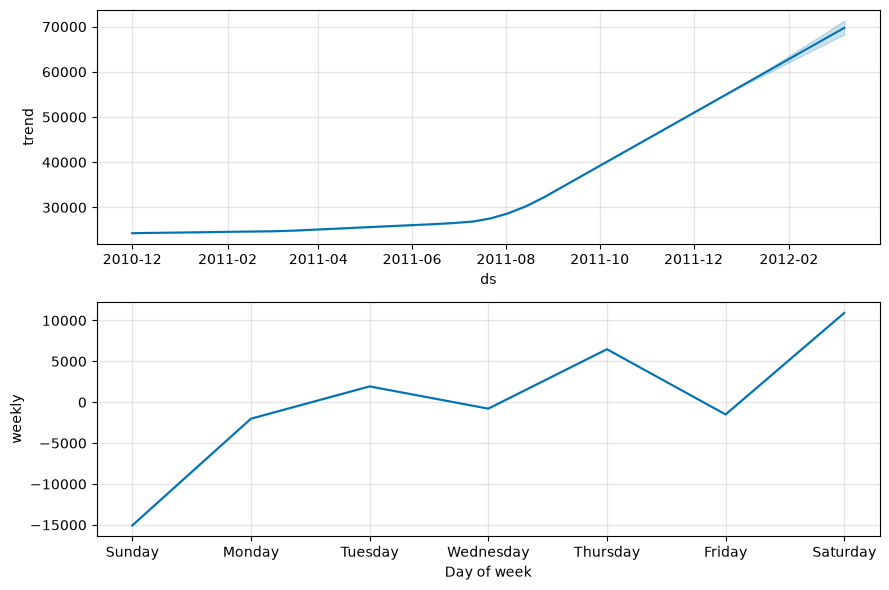

In [14]:
fig = model.plot_components(forecast)
plt.show()

In [15]:
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(30)

,ds,yhat,yhat_lower,yhat_upper
365,2012-02-08,63381.968218,44469.233654,79828.352396
366,2012-02-09,70837.738839,52526.582541,89200.956695
367,2012-02-10,63053.422062,45857.246211,81737.721684
368,2012-02-11,75659.635706,57446.782973,93928.381933
369,2012-02-12,49865.095699,32002.599908,66794.894691
370,2012-02-13,63110.157467,45067.641703,81851.025468
371,2012-02-14,67252.528988,49313.498641,85172.788419
372,2012-02-15,64725.548112,46501.326036,81443.440051
373,2012-02-16,72181.318732,53043.433735,88874.736085
374,2012-02-17,64397.001955,46058.112918,80489.871174


In [16]:
forecast.to_csv("sales_forecast.csv", index=False)
print("Forecast saved successfully.")

Forecast saved successfully.
